In [ ]:
!pip install torch nltk numpy

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import nltk
import re
import random

from collections import Counter
from nltk.translate.bleu_score import corpus_bleu

nltk.download('punkt')

# English-French toy parallel corpus
data = [
    ("hello", "bonjour"),
    ("how are you", "comment allez vous"),
    ("i am fine", "je vais bien"),
    ("good morning", "bonjour"),
    ("thank you", "merci"),
    ("i love you", "je t aime"),
    ("good night", "bonne nuit"),
    ("see you", "a bientot"),
    ("what is your name", "comment vous appelez vous"),
    ("i am happy", "je suis heureux"),
    ("i like apples", "j aime les pommes"),
    ("she is beautiful", "elle est belle"),
    ("he is my friend", "il est mon ami"),
    ("welcome home", "bienvenue chez vous"),
    ("where are you", "ou etes vous")
]

# Tokenization
def tokenize(sentence):
    return re.findall(r"\w+|[^\w\s]", sentence.lower())

pairs = [(tokenize(en), tokenize(fr)) for en, fr in data]

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


In [ ]:
SPECIALS = ["<PAD>", "<SOS>", "<EOS>", "<UNK>"]

def build_vocab(sentences):
    counter = Counter(
        token for sentence in sentences for token in sentence
    )

    vocab = {token: idx for idx, token in enumerate(SPECIALS)}

    for word in counter:
        if word not in vocab:
            vocab[word] = len(vocab)

    return vocab

src_vocab = build_vocab([en for en, fr in pairs])
tgt_vocab = build_vocab([fr for en, fr in pairs])

src_inv = {v: k for k, v in src_vocab.items()}
tgt_inv = {v: k for k, v in tgt_vocab.items()}

PAD = 0
SOS = 1
EOS = 2
UNK = 3

def encode(sentence, vocab):
    return [SOS] + [
        vocab.get(word, UNK) for word in sentence
    ] + [EOS]

dataset = [
    (encode(en, src_vocab), encode(fr, tgt_vocab))
    for en, fr in pairs
]

In [ ]:
class Encoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim):
        super().__init__()

        self.embedding = nn.Embedding(
            input_dim, emb_dim, padding_idx=PAD
        )

        self.lstm = nn.LSTM(
            emb_dim,
            hid_dim,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(hid_dim * 2, hid_dim)

    def forward(self, src):
        embedded = self.embedding(src)

        outputs, (hidden, cell) = self.lstm(embedded)

        # Combine forward and backward states
        hidden = torch.tanh(
            self.fc(torch.cat((hidden[-2], hidden[-1]), dim=1))
        )

        return outputs, hidden

In [ ]:
class Attention(nn.Module):
    def __init__(self, hid_dim):
        super().__init__()

        self.attn = nn.Linear(
            hid_dim * 3, hid_dim
        )

        self.v = nn.Linear(hid_dim, 1, bias=False)

    def forward(self, hidden, encoder_outputs):

        batch_size = encoder_outputs.shape[0]
        src_len = encoder_outputs.shape[1]

        hidden = hidden.unsqueeze(1).repeat(1, src_len, 1)

        energy = torch.tanh(
            self.attn(
                torch.cat((hidden, encoder_outputs), dim=2)
            )
        )

        scores = self.v(energy).squeeze(2)

        attention = torch.softmax(scores, dim=1)

        context = torch.bmm(
            attention.unsqueeze(1), encoder_outputs
        ).squeeze(1)

        return context, attention

In [ ]:
class Decoder(nn.Module):
    def __init__(self, output_dim, emb_dim, hid_dim):
        super().__init__()

        self.embedding = nn.Embedding(
            output_dim, emb_dim, padding_idx=PAD
        )

        self.attention = Attention(hid_dim)

        self.lstm = nn.LSTM(
            emb_dim + hid_dim * 2,
            hid_dim,
            batch_first=True
        )

        self.fc = nn.Linear(
            hid_dim + hid_dim * 2 + emb_dim,
            output_dim
        )

    def forward(self, input, hidden, encoder_outputs):

        input = input.unsqueeze(1)

        embedded = self.embedding(input)

        context, attention = self.attention(
            hidden, encoder_outputs
        )

        lstm_input = torch.cat(
            (embedded, context.unsqueeze(1)), dim=2
        )

        output, (hidden_new, cell) = self.lstm(
            lstm_input
        )

        prediction = self.fc(
            torch.cat(
                (output.squeeze(1),
                 context,
                 embedded.squeeze(1)),
                dim=1
            )
        )

        return prediction, hidden_new.squeeze(0), attention

In [ ]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, trg, teacher_forcing=0.5):

        batch_size = src.shape[0]
        trg_len = trg.shape[1]
        output_dim = len(tgt_vocab)

        outputs = torch.zeros(
            batch_size, trg_len, output_dim
        ).to(src.device)

        encoder_outputs, hidden = self.encoder(src)

        input = trg[:, 0]

        for t in range(1, trg_len):

            prediction, hidden, attention = self.decoder(
                input, hidden, encoder_outputs
            )

            outputs[:, t] = prediction

            teacher_force = random.random() < teacher_forcing

            top1 = prediction.argmax(1)

            input = trg[:, t] if teacher_force else top1

        return outputs

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EMB_DIM = 64
HID_DIM = 128

encoder = Encoder(
    len(src_vocab), EMB_DIM, HID_DIM
)

decoder = Decoder(
    len(tgt_vocab), EMB_DIM, HID_DIM
)

model = Seq2Seq(encoder, decoder).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

criterion = nn.CrossEntropyLoss(ignore_index=PAD)

In [ ]:
from torch.nn.utils.rnn import pad_sequence

def make_batch(dataset):
    src = [torch.tensor(x[0]) for x in dataset]
    trg = [torch.tensor(x[1]) for x in dataset]

    src = pad_sequence(
        src, batch_first=True, padding_value=PAD
    )

    trg = pad_sequence(
        trg, batch_first=True, padding_value=PAD
    )

    return src.to(device), trg.to(device)

In [ ]:
src, trg = make_batch(dataset)

EPOCHS = 300
loss_history = []
for epoch in range(EPOCHS):

    model.train()

    optimizer.zero_grad()

    output = model(src, trg, teacher_forcing=0.5)

    output_dim = output.shape[-1]

    output = output[:, 1:].reshape(-1, output_dim)
    target = trg[:, 1:].reshape(-1)

    loss = criterion(output, target)
    loss_history.append(loss.item())
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(), 1.0
    )

    optimizer.step()

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch: {epoch+1}, Loss: {loss.item():.4f}"
        )

Epoch: 50, Loss: 0.0013
Epoch: 100, Loss: 0.0010
Epoch: 150, Loss: 0.0008
Epoch: 200, Loss: 0.0007
Epoch: 250, Loss: 0.0006
Epoch: 300, Loss: 0.0005


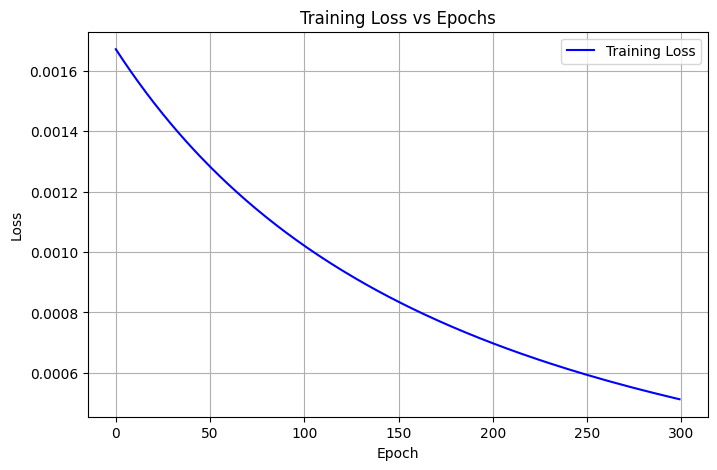

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_history, color='blue', label='Training Loss')

plt.title('Training Loss vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
def translate(sentence):

    model.eval()

    tokens = tokenize(sentence)

    src_ids = encode(tokens, src_vocab)

    src_tensor = torch.tensor(
        [src_ids], dtype=torch.long
    ).to(device)

    with torch.no_grad():

        encoder_outputs, hidden = model.encoder(src_tensor)

        input = torch.tensor([SOS]).to(device)

        result = []

        for _ in range(20):

            prediction, hidden, attention = model.decoder(
                input, hidden, encoder_outputs
            )

            predicted_id = prediction.argmax(1).item()

            if predicted_id == EOS:
                break

            result.append(tgt_inv.get(predicted_id, "<UNK>"))

            input = torch.tensor(
                [predicted_id]
            ).to(device)

    return " ".join(result)


print("Translation:", translate("how are you"))
print("Translation:", translate("i love you"))
print("Translation:", translate("good morning"))

Translation: comment allez vous
Translation: je t aime
Translation: bonjour


In [ ]:
references = []
hypotheses = []

for en, fr in pairs:

    predicted = translate(" ".join(en))

    references.append([fr])
    hypotheses.append(tokenize(predicted))

bleu = corpus_bleu(
    references,
    hypotheses
)

print("BLEU Score:", bleu)
print("BLEU Percentage:", bleu * 100)

BLEU Score: 0.5992674720618411
BLEU Percentage: 59.9267472061841
